# El Niño Shoreline Project: Locked Test Set (Simplified)

1. **Lock away** the test data.
2. **Cross-validate** each model on the training data (to compare models).
3. **Train** each model on all the training data.
4. **Test once** on the locked data.

| | Locked test data | Training data | Cross-validation |
|---|---|---|---|
| **Question 1** (new winter) | last 4 winters | other 17 winters | leave-one-winter-out |
| **Question 2** (new coastline) | 22 random coastal sections | other 88 sections | 10 folds, grouped by section |

The trained models and their test predictions are saved to `models/locked_test/` for the live demo.

Run time: about 25–45 minutes (mostly the GBT).

## 1. Setup

In [1]:
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV, GroupKFold, LeaveOneGroupOut, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import SplineTransformer, StandardScaler

ROOT_DIR  = Path.cwd().parent           # this notebook lives in scripts/
DATA_PATH = ROOT_DIR / "processed" / "final_modeling_dataset.csv"
TARGET    = "shoreline_change_m"

BEACH           = ["BeachWidth_m", "beach_slope", "shore_orientation_sin", "shore_orientation_cos"]
BEACH_WAVE      = BEACH + ["winter_wave_power", "wave_dir_sin", "wave_dir_cos"]
BEACH_WAVE_RONI = BEACH_WAVE + ["RONI"]

# Where the trained models and predictions are saved (used by the live demo)
Q1_SAVE_FOLDER = ROOT_DIR / "models" / "locked_test" / "q1_last_4_winters"
Q2_SAVE_FOLDER = ROOT_DIR / "models" / "locked_test" / "q2_22_random_sections"
Q1_SAVE_FOLDER.mkdir(parents=True, exist_ok=True)
Q2_SAVE_FOLDER.mkdir(parents=True, exist_ok=True)

## 2. Load the data and remove outliers

In [2]:
df = pd.read_csv(DATA_PATH)
df = df[df[TARGET].abs() <= 50]                 # drop rows where |change| is above 50 m
df = df.reset_index(drop=True)
df["section"] = df["transect_id"].str[:11]      # first 11 characters = coastal section

print("Rows:", len(df))

Rows: 60584


## 3. Lock away the test data

In [3]:
# Question 1: lock away the last 4 winters
Q1_TEST_WINTERS = ["2017-2018", "2018-2019", "2019-2020", "2020-2021"]

q1_test  = df[df["winter"].isin(Q1_TEST_WINTERS)]
q1_train = df[~df["winter"].isin(Q1_TEST_WINTERS)]

# Question 2: lock away 22 coastal sections (picked at random with seed 42)
Q2_TEST_SECTIONS = ["usa_CA_0008", "usa_CA_0009", "usa_CA_0010", "usa_CA_0014", "usa_CA_0020", "usa_CA_0049",
                    "usa_CA_0058", "usa_CA_0062", "usa_CA_0063", "usa_CA_0064", "usa_CA_0069", "usa_CA_0076",
                    "usa_CA_0082", "usa_CA_0089", "usa_CA_0090", "usa_CA_0094", "usa_CA_0097", "usa_CA_0098",
                    "usa_CA_0106", "usa_CA_0109", "usa_CA_0114", "usa_CA_0126"]

q2_test  = df[df["section"].isin(Q2_TEST_SECTIONS)]
q2_train = df[~df["section"].isin(Q2_TEST_SECTIONS)]

print("Question 1: training rows =", len(q1_train), "| locked test rows =", len(q1_test))
print("Question 2: training rows =", len(q2_train), "| locked test rows =", len(q2_test))

Question 1: training rows = 48089 | locked test rows = 12495
Question 2: training rows = 43927 | locked test rows = 16657


## 4. The models and their settings

| Model | What it does |
|---|---|
| **Baseline: overall average** | Predicts the same number for every row: the average change in the training data |
| **Baseline: transect average** | Predicts each transect's own average change in the training winters |
| **Linear regression** | Fits a straight-line relationship between each feature and shoreline change |
| **GAM** | Gives each feature its own smooth curve and adds the curves together, so effects can bend but stay easy to read |
| **Random forest** | Averages many decision trees, each trained on a random sample of rows and features |
| **Gradient-boosted tree (GBT)** | Builds small trees one after another, each one correcting the errors of the trees before it; its settings are tuned with a grid search |
| **Transect average + model** | Starts from each transect's average, then uses a second model (with or without RONI) to predict how this winter differs from normal |

In [4]:
# Baseline: each transect's average change in the training data
class TransectAverage(BaseEstimator, RegressorMixin):
    def fit(self, X, y):
        training = pd.DataFrame({"transect_id": X["transect_id"].values, "change": np.asarray(y)})
        self.averages_ = training.groupby("transect_id")["change"].mean()
        self.overall_ = training["change"].mean()      # backup for transects never seen
        return self

    def predict(self, X):
        predictions = X["transect_id"].map(self.averages_)
        predictions = predictions.fillna(self.overall_)
        return predictions.to_numpy()


# Transect average + a second model that predicts each row's difference from its transect's average
class TransectAveragePlus(BaseEstimator, RegressorMixin):
    def __init__(self, model=None, features=None):
        self.model = model
        self.features = features

    def fit(self, X, y):
        y = pd.Series(np.asarray(y), index=X.index)
        self.means_ = y.groupby(X["transect_id"]).mean()
        self.overall_ = float(y.mean())
        leftovers = y - X["transect_id"].map(self.means_)
        self.model_ = clone(self.model).fit(X[self.features], leftovers)
        return self

    def predict(self, X):
        normal = X["transect_id"].map(self.means_).fillna(self.overall_).to_numpy()
        return normal + self.model_.predict(X[self.features])

In [5]:
linear = make_pipeline(
    SimpleImputer(strategy="median"),       # fill missing values with the median
    StandardScaler(),                       # put every feature on the same scale
    LinearRegression(),
)

gam = make_pipeline(
    SimpleImputer(strategy="median"),
    SplineTransformer(knots="quantile"),    # turn each feature into a smooth curve
    Ridge(),                                # fit the curves, keeping them smooth
)

rf = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestRegressor(n_estimators=100, min_samples_leaf=50, max_features=0.5, n_jobs=-1, random_state=42),
)

gbt = GridSearchCV(
    HistGradientBoostingRegressor(learning_rate=0.05, max_iter=300, early_stopping=True,
                                  validation_fraction=0.1, n_iter_no_change=20, random_state=42),
    param_grid={"max_leaf_nodes": [15, 31], "min_samples_leaf": [100, 500]},
    cv=GroupKFold(n_splits=3),
    scoring="neg_mean_absolute_error",
)

small_gbt = HistGradientBoostingRegressor(learning_rate=0.05, max_iter=300, max_leaf_nodes=15,
                                          min_samples_leaf=500, random_state=42)

## 5. Create the evaluate function for question 1 and question 2

`q1_evaluate` and `q2_evaluate` do steps 2–4 for one model:
cross-validate on the training data, train on all the training data, then test once on the locked data.
Each one also:
- records the **training score** (how well the model fits the data it learned from)
- saves the trained model to the demo folder, and keeps its test predictions

In [6]:
def file_name(model_name):
    """Turn a model name into a file name, e.g. "GBT: beach + wave" -> "gbt_beach_wave.pkl"."""
    name = model_name.lower().replace(" + ", "_").replace(": ", "_").replace(" ", "_")
    name = name.replace("(", "").replace(")", "")
    return name + ".pkl"


q1_results = []              # scores for every Question 1 model
q1_final_models = {}         # the trained models
q1_test_predictions = {}     # their predictions for the locked winters
q1_model_info = {}           # which features each saved model uses

def q1_evaluate(name, model, features, needs_groups=False):
    groups = q1_train["winter"]
    if needs_groups:
        extra = {"groups": groups}            # the GBT's tuning keeps winters together too
    else:
        extra = None

    # Step 2: cross-validation on the training winters
    cv_predictions = cross_val_predict(model, q1_train[features], q1_train[TARGET],
                                       groups=groups, cv=LeaveOneGroupOut(), params=extra)
    # Step 3: train on all the training winters
    final_model = clone(model)
    if needs_groups:
        final_model.fit(q1_train[features], q1_train[TARGET], groups=groups)
    else:
        final_model.fit(q1_train[features], q1_train[TARGET])
    # Step 4: test once on the locked winters
    test_predictions = final_model.predict(q1_test[features])

    result = {
        "model": name,
        "Train R²": r2_score(q1_train[TARGET], final_model.predict(q1_train[features])),
        "CV R²": r2_score(q1_train[TARGET], cv_predictions),
        "CV MAE (m)": mean_absolute_error(q1_train[TARGET], cv_predictions),
        "Test R²": r2_score(q1_test[TARGET], test_predictions),
        "Test MAE (m)": mean_absolute_error(q1_test[TARGET], test_predictions),
    }
    q1_results.append(result)

    # Save the trained model (for the GBT, only the winning settings) and keep its predictions
    if needs_groups:
        joblib.dump(final_model.best_estimator_, Q1_SAVE_FOLDER / file_name(name), compress=3)
    else:
        joblib.dump(final_model, Q1_SAVE_FOLDER / file_name(name), compress=3)
    q1_final_models[name] = final_model
    q1_test_predictions[name] = test_predictions
    q1_model_info[file_name(name)] = {"model": name, "features": features}

    print(f"{name:48s} CV R² = {result['CV R²']:6.3f}   Test R² = {result['Test R²']:6.3f}")


q2_results = []
q2_final_models = {}
q2_test_predictions = {}
q2_model_info = {}

def q2_evaluate(name, model, features, needs_groups=False):
    groups = q2_train["section"]
    if needs_groups:
        extra = {"groups": groups}            # the GBT's tuning keeps sections together too
    else:
        extra = None

    # Step 2: cross-validation on the training sections
    cv_predictions = cross_val_predict(model, q2_train[features], q2_train[TARGET],
                                       groups=groups, cv=GroupKFold(n_splits=10), params=extra)
    # Step 3: train on all the training sections
    final_model = clone(model)
    if needs_groups:
        final_model.fit(q2_train[features], q2_train[TARGET], groups=groups)
    else:
        final_model.fit(q2_train[features], q2_train[TARGET])
    # Step 4: test once on the locked sections
    test_predictions = final_model.predict(q2_test[features])

    result = {
        "model": name,
        "Train R²": r2_score(q2_train[TARGET], final_model.predict(q2_train[features])),
        "CV R²": r2_score(q2_train[TARGET], cv_predictions),
        "CV MAE (m)": mean_absolute_error(q2_train[TARGET], cv_predictions),
        "Test R²": r2_score(q2_test[TARGET], test_predictions),
        "Test MAE (m)": mean_absolute_error(q2_test[TARGET], test_predictions),
    }
    q2_results.append(result)

    if needs_groups:
        joblib.dump(final_model.best_estimator_, Q2_SAVE_FOLDER / file_name(name), compress=3)
    else:
        joblib.dump(final_model, Q2_SAVE_FOLDER / file_name(name), compress=3)
    q2_final_models[name] = final_model
    q2_test_predictions[name] = test_predictions
    q2_model_info[file_name(name)] = {"model": name, "features": features}

    print(f"{name:30s} CV R² = {result['CV R²']:6.3f}   Test R² = {result['Test R²']:6.3f}")

---
# Question 1: Does El Niño (RONI) help predict a new winter?

## 6. Baselines

In [7]:
q1_evaluate("Baseline: overall average",  DummyRegressor(strategy="mean"), ["RONI"])
q1_evaluate("Baseline: transect average", TransectAverage(),               ["transect_id"])

Baseline: overall average                        CV R² = -0.009   Test R² = -0.010
Baseline: transect average                       CV R² =  0.451   Test R² =  0.449


## 7. Linear regression

In [8]:
q1_evaluate("Linear: beach",               linear, BEACH)
q1_evaluate("Linear: beach + wave",        linear, BEACH_WAVE)
q1_evaluate("Linear: beach + wave + RONI", linear, BEACH_WAVE_RONI)

Linear: beach                                    CV R² =  0.024   Test R² =  0.034
Linear: beach + wave                             CV R² =  0.049   Test R² =  0.054
Linear: beach + wave + RONI                      CV R² =  0.040   Test R² =  0.055


## 8. GAM

In [9]:
q1_evaluate("GAM: beach",               gam, BEACH)
q1_evaluate("GAM: beach + wave",        gam, BEACH_WAVE)
q1_evaluate("GAM: beach + wave + RONI", gam, BEACH_WAVE_RONI)

GAM: beach                                       CV R² =  0.083   Test R² =  0.067
GAM: beach + wave                                CV R² =  0.107   Test R² =  0.082
GAM: beach + wave + RONI                         CV R² =  0.074   Test R² =  0.125


## 9. Random forest (a few minutes)

In [10]:
q1_evaluate("RF: beach",               rf, BEACH)
q1_evaluate("RF: beach + wave",        rf, BEACH_WAVE)
q1_evaluate("RF: beach + wave + RONI", rf, BEACH_WAVE_RONI)

RF: beach                                        CV R² =  0.315   Test R² =  0.302
RF: beach + wave                                 CV R² =  0.382   Test R² =  0.375
RF: beach + wave + RONI                          CV R² =  0.241   Test R² =  0.287


## 10. Gradient-boosted tree (slow: tuning runs inside every fold)

In [11]:
q1_evaluate("GBT: beach",               gbt, BEACH,           needs_groups=True)
q1_evaluate("GBT: beach + wave",        gbt, BEACH_WAVE,      needs_groups=True)
q1_evaluate("GBT: beach + wave + RONI", gbt, BEACH_WAVE_RONI, needs_groups=True)

GBT: beach                                       CV R² =  0.323   Test R² =  0.306
GBT: beach + wave                                CV R² =  0.395   Test R² =  0.385
GBT: beach + wave + RONI                         CV R² =  0.295   Test R² =  0.356


## 11. Transect average + RONI

In [12]:
q1_evaluate("Transect average + linear RONI",
            TransectAveragePlus(LinearRegression(), ["RONI"]),
            ["transect_id", "RONI"])
q1_evaluate("Transect average + GBT beach + wave (control)",
            TransectAveragePlus(small_gbt, BEACH_WAVE),
            ["transect_id"] + BEACH_WAVE)
q1_evaluate("Transect average + GBT beach + wave + RONI",
            TransectAveragePlus(small_gbt, BEACH_WAVE_RONI),
            ["transect_id"] + BEACH_WAVE_RONI)

Transect average + linear RONI                   CV R² =  0.442   Test R² =  0.450
Transect average + GBT beach + wave (control)    CV R² =  0.451   Test R² =  0.449
Transect average + GBT beach + wave + RONI       CV R² =  0.374   Test R² =  0.439


## 12. Question 1 results

In [13]:
q1_table = pd.DataFrame(q1_results).set_index("model")
q1_table.round(3)

,Train R²,CV R²,CV MAE (m),Test R²,Test MAE (m)
model,,,,,
Baseline: overall average,0.000,-0.009,7.969,-0.010,8.152
Baseline: transect average,0.524,0.451,5.844,0.449,6.070
Linear: beach,0.036,0.024,7.820,0.034,7.927
Linear: beach + wave,0.062,0.049,7.746,0.054,7.872
Linear: beach + wave + RONI,0.063,0.040,7.797,0.055,7.871
GAM: beach,0.097,0.083,7.546,0.067,7.740
GAM: beach + wave,0.125,0.107,7.480,0.082,7.705
GAM: beach + wave + RONI,0.152,0.074,7.667,0.125,7.437
RF: beach,0.362,0.315,6.483,0.302,6.772


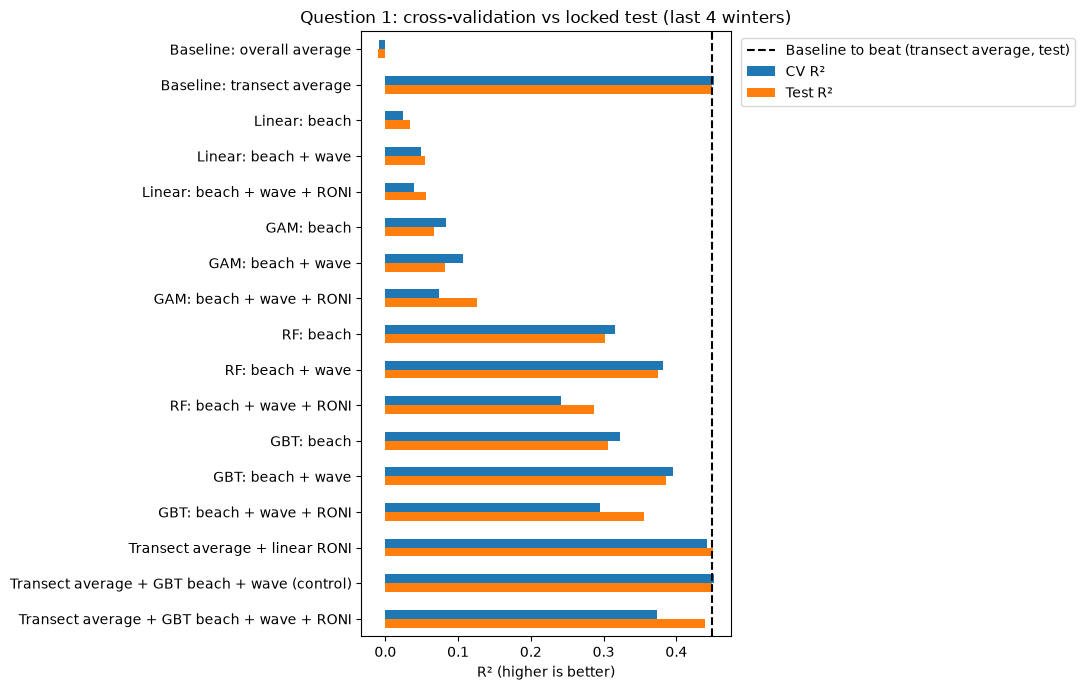

In [14]:
ax = q1_table[["CV R²", "Test R²"]].plot.barh(figsize=(11, 7))
ax.axvline(q1_table.loc["Baseline: transect average", "Test R²"], color="black", linestyle="--",
           label="Baseline to beat (transect average, test)")
ax.invert_yaxis()
ax.set_xlabel("R² (higher is better)")
ax.set_ylabel("")
ax.set_title("Question 1: cross-validation vs locked test (last 4 winters)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

### Does adding RONI help? (change in R²; negative = RONI made it worse)

In [15]:
r2 = q1_table["Test R²"]
cv = q1_table["CV R²"]

roni_effect = pd.DataFrame({
    "CV change": {
        "Transect average":       cv["Transect average + linear RONI"] - cv["Baseline: transect average"],
        "Transect average + GBT": cv["Transect average + GBT beach + wave + RONI"] - cv["Transect average + GBT beach + wave (control)"],
        "Linear":                 cv["Linear: beach + wave + RONI"] - cv["Linear: beach + wave"],
        "GAM":                    cv["GAM: beach + wave + RONI"] - cv["GAM: beach + wave"],
        "Random forest":          cv["RF: beach + wave + RONI"] - cv["RF: beach + wave"],
        "GBT":                    cv["GBT: beach + wave + RONI"] - cv["GBT: beach + wave"],
    },
    "Test change": {
        "Transect average":       r2["Transect average + linear RONI"] - r2["Baseline: transect average"],
        "Transect average + GBT": r2["Transect average + GBT beach + wave + RONI"] - r2["Transect average + GBT beach + wave (control)"],
        "Linear":                 r2["Linear: beach + wave + RONI"] - r2["Linear: beach + wave"],
        "GAM":                    r2["GAM: beach + wave + RONI"] - r2["GAM: beach + wave"],
        "Random forest":          r2["RF: beach + wave + RONI"] - r2["RF: beach + wave"],
        "GBT":                    r2["GBT: beach + wave + RONI"] - r2["GBT: beach + wave"],
    },
})
roni_effect.round(3)

,CV change,Test change
Transect average,-0.009,0.001
Transect average + GBT,-0.077,-0.010
Linear,-0.009,0.001
GAM,-0.034,0.043
Random forest,-0.141,-0.087
GBT,-0.100,-0.029


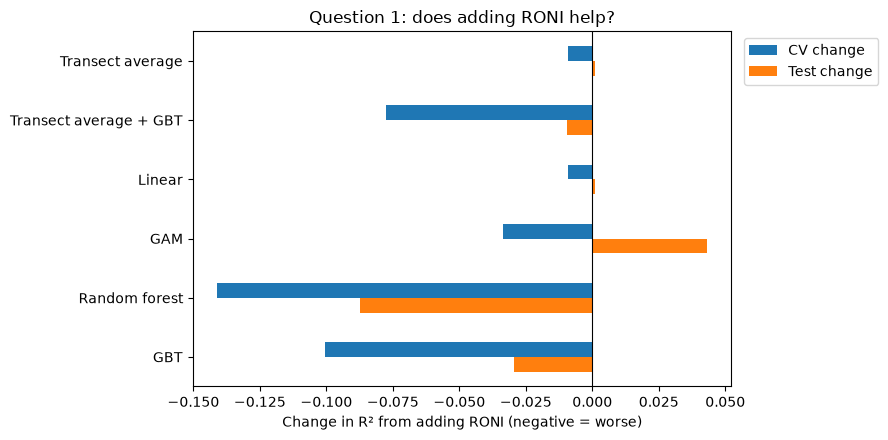

In [16]:
ax = roni_effect.plot.barh(figsize=(9, 4.5))
ax.axvline(0, color="black", linewidth=0.8)
ax.invert_yaxis()
ax.set_ylabel("")
ax.set_xlabel("Change in R² from adding RONI (negative = worse)")
ax.set_title("Question 1: does adding RONI help?")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

## 13. Training vs. test scores (overfitting check)

**Train R²** = score on the same winters the model learned from. **Test R²** = score on the locked winters.
A big gap means the model memorized the training data instead of learning patterns that carry over.

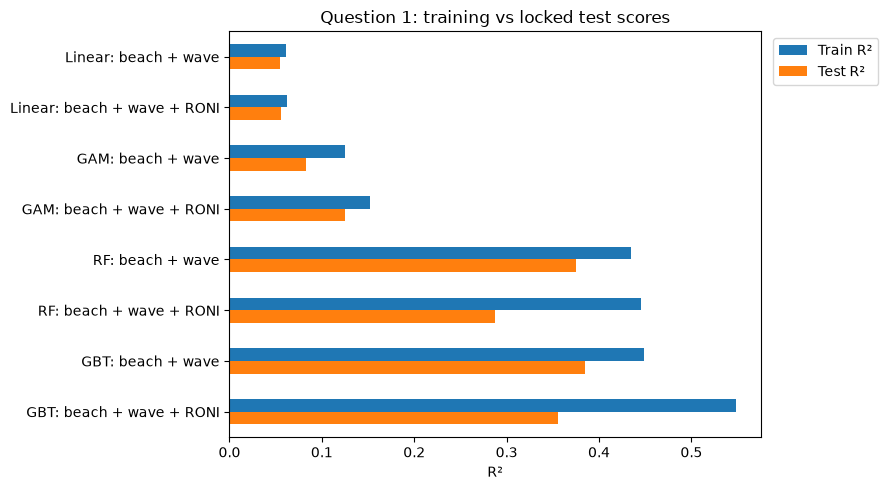

In [17]:
models_to_compare = ["Linear: beach + wave", "Linear: beach + wave + RONI",
                     "GAM: beach + wave",    "GAM: beach + wave + RONI",
                     "RF: beach + wave",     "RF: beach + wave + RONI",
                     "GBT: beach + wave",    "GBT: beach + wave + RONI"]

ax = q1_table.loc[models_to_compare, ["Train R²", "Test R²"]].plot.barh(figsize=(9, 5))
ax.invert_yaxis()
ax.set_ylabel("")
ax.set_xlabel("R²")
ax.set_title("Question 1: training vs locked test scores")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

## 14. Winter by winter

Average error (MAE, lower is better) in each locked winter. Does RONI help in El Niño winters or La Niña winters?

In [18]:
errors = q1_test[["winter", "RONI"]].copy()
errors["Baseline (transect average)"] = (q1_test[TARGET] - q1_test_predictions["Baseline: transect average"]).abs()
errors["GAM, no RONI"]   = (q1_test[TARGET] - q1_test_predictions["GAM: beach + wave"]).abs()
errors["GAM, with RONI"] = (q1_test[TARGET] - q1_test_predictions["GAM: beach + wave + RONI"]).abs()
errors["GBT, no RONI"]   = (q1_test[TARGET] - q1_test_predictions["GBT: beach + wave"]).abs()
errors["GBT, with RONI"] = (q1_test[TARGET] - q1_test_predictions["GBT: beach + wave + RONI"]).abs()

winter_table = errors.groupby("winter").mean()
winter_table.round(2)

,RONI,Baseline (transect average),"GAM, no RONI","GAM, with RONI","GBT, no RONI","GBT, with RONI"
winter,,,,,,
2017-2018,-1.02,5.88,7.07,6.91,6.07,5.65
2018-2019,0.70,6.32,8.95,8.96,7.08,7.15
2019-2020,0.14,6.92,7.52,6.49,6.82,6.92
2020-2021,-1.30,5.17,7.33,7.46,5.68,6.52


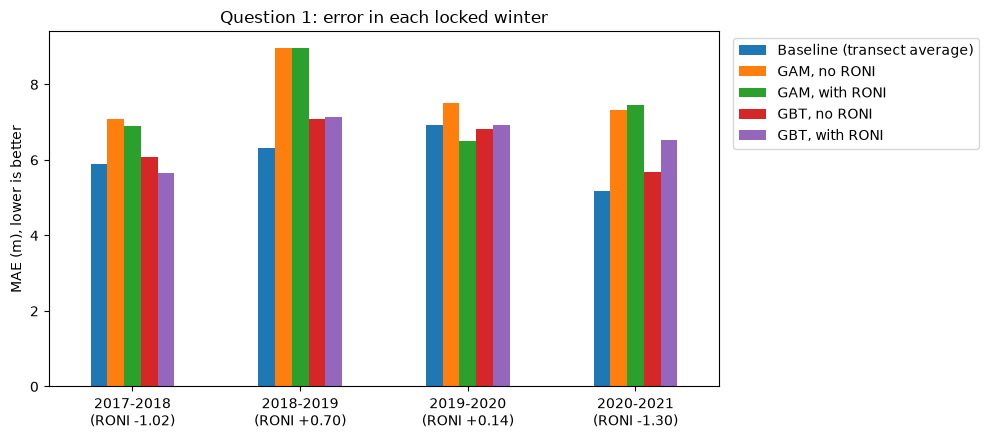

In [19]:
ax = winter_table.drop(columns="RONI").plot.bar(figsize=(10, 4.5), rot=0)
ax.set_xticklabels([f"{winter}\n(RONI {roni:+.2f})" for winter, roni in winter_table["RONI"].items()])
ax.set_xlabel("")
ax.set_ylabel("MAE (m), lower is better")
ax.set_title("Question 1: error in each locked winter")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

## 15. The shape of the RONI effect the GAM learned

Keep every feature at a typical (median) value and change only RONI. The line is the GAM's prediction;
the dots are each winter's actual average change (training winters and locked winters).

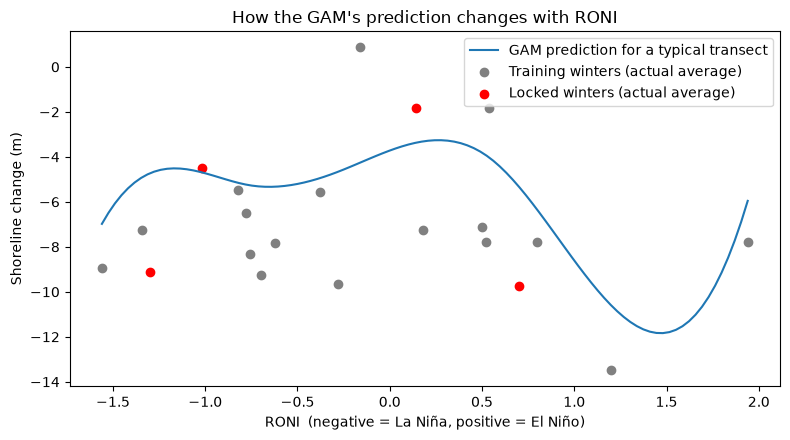

In [20]:
gam_roni = q1_final_models["GAM: beach + wave + RONI"]

roni_values = np.linspace(df["RONI"].min(), df["RONI"].max(), 100)
typical_beach = pd.DataFrame([q1_train[BEACH_WAVE_RONI].median()] * len(roni_values)).reset_index(drop=True)
typical_beach["RONI"] = roni_values

train_winters = q1_train.groupby("winter").agg(RONI=("RONI", "first"), change=(TARGET, "mean"))
test_winters  = q1_test.groupby("winter").agg(RONI=("RONI", "first"), change=(TARGET, "mean"))

plt.figure(figsize=(8, 4.5))
plt.plot(roni_values, gam_roni.predict(typical_beach), label="GAM prediction for a typical transect")
plt.scatter(train_winters["RONI"], train_winters["change"], color="gray", label="Training winters (actual average)")
plt.scatter(test_winters["RONI"], test_winters["change"], color="red", label="Locked winters (actual average)")
plt.xlabel("RONI  (negative = La Niña, positive = El Niño)")
plt.ylabel("Shoreline change (m)")
plt.title("How the GAM's prediction changes with RONI")
plt.legend()
plt.tight_layout()
plt.show()

## 16. Save the Question 1 results and predictions (for the demo)

In [21]:
id_columns = ["transect_id", "section", "winter"]

q1_test[id_columns + BEACH_WAVE_RONI + [TARGET]].to_csv(Q1_SAVE_FOLDER / "test_rows.csv", index=False)

prediction_table = q1_test[id_columns + ["RONI", TARGET]].copy()
for_saving = pd.DataFrame(q1_test_predictions, index=q1_test.index)     # one column per model
prediction_table = pd.concat([prediction_table, for_saving], axis=1)
prediction_table.to_csv(Q1_SAVE_FOLDER / "test_predictions.csv", index=False)

q1_model_info["locked test set"] = "B: last 4 winters"
q1_model_info["locked winters"] = Q1_TEST_WINTERS
q1_model_info["sklearn_version"] = sklearn.__version__
with open(Q1_SAVE_FOLDER / "model_info.json", "w") as f:
    json.dump(q1_model_info, f, indent=2)

q1_table.reset_index().assign(**{"test set": "B: last 4 winters"}).to_csv(
    ROOT_DIR / "models" / "locked_test" / "q1_results.csv", index=False)

print("Saved", len(q1_test_predictions), "models, test rows and predictions to models/locked_test/q1_last_4_winters/")

Saved 17 models, test rows and predictions to models/locked_test/q1_last_4_winters/


---
# Question 2: Do beach and wave features explain shoreline change on new coastline?

## 17. Baseline

In [22]:
q2_evaluate("Baseline: overall average", DummyRegressor(strategy="mean"), ["RONI"])

Baseline: overall average      CV R² = -0.013   Test R² = -0.010


## 18. Linear regression

In [23]:
q2_evaluate("Linear: beach",        linear, BEACH)
q2_evaluate("Linear: beach + wave", linear, BEACH_WAVE)

Linear: beach                  CV R² = -0.002   Test R² =  0.037
Linear: beach + wave           CV R² =  0.010   Test R² =  0.040


## 19. GAM

In [24]:
q2_evaluate("GAM: beach",        gam, BEACH)
q2_evaluate("GAM: beach + wave", gam, BEACH_WAVE)

GAM: beach                     CV R² =  0.028   Test R² =  0.090
GAM: beach + wave              CV R² =  0.033   Test R² =  0.004


## 20. Random forest

In [25]:
q2_evaluate("RF: beach",        rf, BEACH)
q2_evaluate("RF: beach + wave", rf, BEACH_WAVE)

RF: beach                      CV R² = -0.046   Test R² = -0.013
RF: beach + wave               CV R² = -0.029   Test R² =  0.017


## 21. Gradient-boosted tree

In [26]:
q2_evaluate("GBT: beach",        gbt, BEACH,      needs_groups=True)
q2_evaluate("GBT: beach + wave", gbt, BEACH_WAVE, needs_groups=True)

GBT: beach                     CV R² = -0.035   Test R² = -0.002
GBT: beach + wave              CV R² = -0.039   Test R² =  0.009


## 22. Question 2 results

In [27]:
q2_table = pd.DataFrame(q2_results).set_index("model")
q2_table.round(3)

,Train R²,CV R²,CV MAE (m),Test R²,Test MAE (m)
model,,,,,
Baseline: overall average,0.000,-0.013,8.073,-0.010,7.760
Linear: beach,0.034,-0.002,8.008,0.037,7.596
Linear: beach + wave,0.064,0.010,8.009,0.040,7.612
GAM: beach,0.087,0.028,7.864,0.090,7.362
GAM: beach + wave,0.128,0.033,7.907,0.004,7.661
RF: beach,0.375,-0.046,8.215,-0.013,7.773
RF: beach + wave,0.445,-0.029,8.207,0.017,7.681
GBT: beach,0.270,-0.035,8.140,-0.002,7.733
GBT: beach + wave,0.402,-0.039,8.235,0.009,7.756


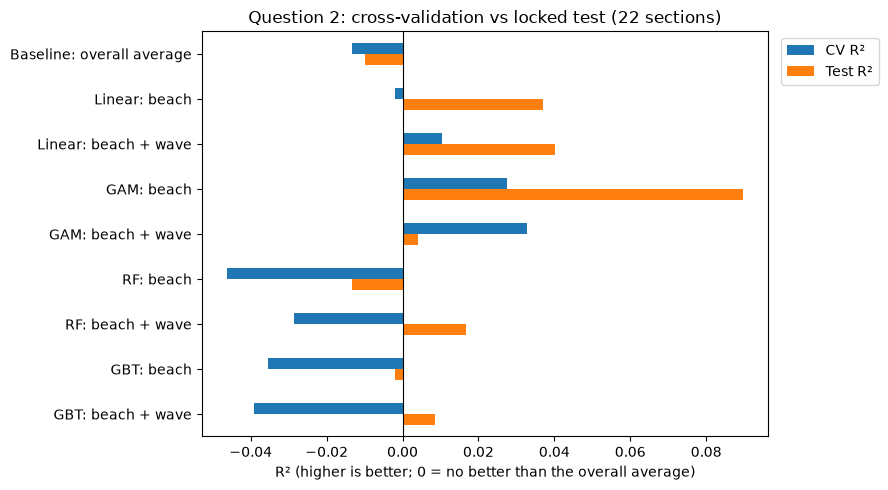

In [28]:
ax = q2_table[["CV R²", "Test R²"]].plot.barh(figsize=(9, 5))
ax.axvline(0, color="black", linewidth=0.8)
ax.invert_yaxis()
ax.set_ylabel("")
ax.set_xlabel("R² (higher is better; 0 = no better than the overall average)")
ax.set_title("Question 2: cross-validation vs locked test (22 sections)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

## 23. Which features matter on new coastline? (drop-column importance)

For each feature: retrain the model **without it** and measure how much the error on unseen sections grows
(10-fold cross-validation grouped by section, on the 88 training sections only).
- **Positive** = the model does worse without the feature, so the feature carries useful information.
- **Near zero or negative** = the model does just as well without it.

The GBT here uses fixed settings (no grid search), so it doesn't have to be tuned again for every feature.

In [29]:
def q2_cv_error(model, features):
    """Cross-validated MAE on the training sections."""
    predictions = cross_val_predict(model, q2_train[features], q2_train[TARGET],
                                    groups=q2_train["section"], cv=GroupKFold(n_splits=10))
    return mean_absolute_error(q2_train[TARGET], predictions)

def without(feature):
    """The beach + wave features, minus one."""
    features = BEACH_WAVE.copy()
    features.remove(feature)
    return features

In [30]:
gam_all_features = q2_cv_error(gam, BEACH_WAVE)
gam_importance = pd.Series({
    "BeachWidth_m":          q2_cv_error(gam, without("BeachWidth_m"))          - gam_all_features,
    "beach_slope":           q2_cv_error(gam, without("beach_slope"))           - gam_all_features,
    "shore_orientation_sin": q2_cv_error(gam, without("shore_orientation_sin")) - gam_all_features,
    "shore_orientation_cos": q2_cv_error(gam, without("shore_orientation_cos")) - gam_all_features,
    "winter_wave_power":     q2_cv_error(gam, without("winter_wave_power"))     - gam_all_features,
    "wave_dir_sin":          q2_cv_error(gam, without("wave_dir_sin"))          - gam_all_features,
    "wave_dir_cos":          q2_cv_error(gam, without("wave_dir_cos"))          - gam_all_features,
})
print("GAM done")

GAM done


In [31]:
gbt_all_features = q2_cv_error(small_gbt, BEACH_WAVE)
gbt_importance = pd.Series({
    "BeachWidth_m":          q2_cv_error(small_gbt, without("BeachWidth_m"))          - gbt_all_features,
    "beach_slope":           q2_cv_error(small_gbt, without("beach_slope"))           - gbt_all_features,
    "shore_orientation_sin": q2_cv_error(small_gbt, without("shore_orientation_sin")) - gbt_all_features,
    "shore_orientation_cos": q2_cv_error(small_gbt, without("shore_orientation_cos")) - gbt_all_features,
    "winter_wave_power":     q2_cv_error(small_gbt, without("winter_wave_power"))     - gbt_all_features,
    "wave_dir_sin":          q2_cv_error(small_gbt, without("wave_dir_sin"))          - gbt_all_features,
    "wave_dir_cos":          q2_cv_error(small_gbt, without("wave_dir_cos"))          - gbt_all_features,
})
print("GBT done")

GBT done


In [32]:
importance = pd.DataFrame({"GAM": gam_importance, "GBT": gbt_importance}).sort_values("GAM", ascending=False)
importance.rename_axis("feature").to_csv(ROOT_DIR / "models" / "locked_test" / "q2_feature_importance.csv")   # for the demo app
importance.round(3)

,GAM,GBT
wave_dir_sin,0.061,0.053
beach_slope,0.041,0.180
winter_wave_power,0.018,-0.081
wave_dir_cos,-0.008,-0.030
BeachWidth_m,-0.010,0.037
shore_orientation_cos,-0.012,0.038
shore_orientation_sin,-0.016,0.001


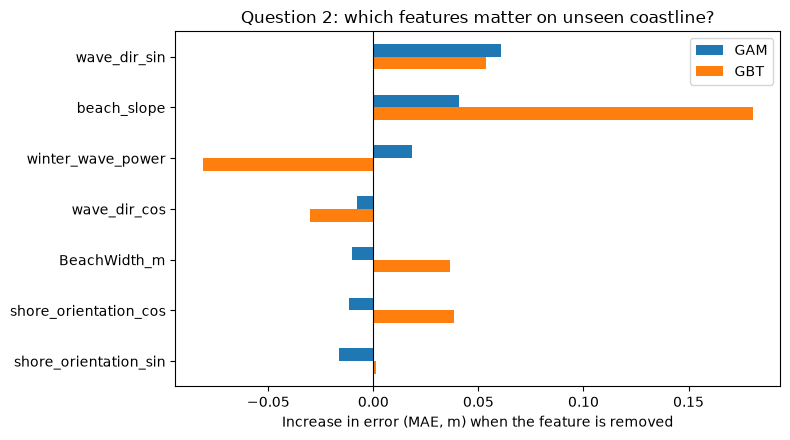

In [33]:
ax = importance.plot.barh(figsize=(8, 4.5))
ax.axvline(0, color="black", linewidth=0.8)
ax.invert_yaxis()
ax.set_xlabel("Increase in error (MAE, m) when the feature is removed")
ax.set_title("Question 2: which features matter on unseen coastline?")
plt.tight_layout()
plt.show()

## 24. Save the Question 2 results and predictions (for the demo)

In [34]:
q2_test[id_columns + BEACH_WAVE_RONI + [TARGET]].to_csv(Q2_SAVE_FOLDER / "test_rows.csv", index=False)

prediction_table = q2_test[id_columns + ["RONI", TARGET]].copy()
for_saving = pd.DataFrame(q2_test_predictions, index=q2_test.index)
prediction_table = pd.concat([prediction_table, for_saving], axis=1)
prediction_table.to_csv(Q2_SAVE_FOLDER / "test_predictions.csv", index=False)

q2_model_info["locked test set"] = "A: 22 random sections"
q2_model_info["locked sections"] = Q2_TEST_SECTIONS
q2_model_info["sklearn_version"] = sklearn.__version__
with open(Q2_SAVE_FOLDER / "model_info.json", "w") as f:
    json.dump(q2_model_info, f, indent=2)

q2_table.reset_index().assign(**{"test set": "A: 22 random sections"}).to_csv(
    ROOT_DIR / "models" / "locked_test" / "q2_results.csv", index=False)

print("Saved", len(q2_test_predictions), "models, test rows and predictions to models/locked_test/q2_22_random_sections/")

Saved 9 models, test rows and predictions to models/locked_test/q2_22_random_sections/


---
# 25. Summary of findings

In [35]:
print("QUESTION 1: Does El Niño (RONI) help predict a new winter?  (locked test: last 4 winters)")
print(f"  Baseline (transect average):   Test R² = {q1_table.loc['Baseline: transect average', 'Test R²']:.3f}")
print(f"  GBT without RONI:              Test R² = {q1_table.loc['GBT: beach + wave', 'Test R²']:.3f}")
print(f"  GBT with RONI:                 Test R² = {q1_table.loc['GBT: beach + wave + RONI', 'Test R²']:.3f}")
print("  Change in Test R² from adding RONI:")
print(roni_effect["Test change"].round(3).to_string())
print()
print("QUESTION 2: Do beach and wave features explain shoreline change on new coastline?  (locked test: 22 sections)")
print(f"  Baseline (overall average): Test R² = {q2_table.loc['Baseline: overall average', 'Test R²']:.3f}")
print(f"  Best model: {q2_table['Test R²'].idxmax()}, Test R² = {q2_table['Test R²'].max():.3f}")
print(f"  Most important feature: GAM = {importance['GAM'].idxmax()}, GBT = {importance['GBT'].idxmax()}")

QUESTION 1: Does El Niño (RONI) help predict a new winter?  (locked test: last 4 winters)
  Baseline (transect average):   Test R² = 0.449
  GBT without RONI:              Test R² = 0.385
  GBT with RONI:                 Test R² = 0.356
  Change in Test R² from adding RONI:
Transect average          0.001
Transect average + GBT   -0.010
Linear                    0.001
GAM                       0.043
Random forest            -0.087
GBT                      -0.029

QUESTION 2: Do beach and wave features explain shoreline change on new coastline?  (locked test: 22 sections)
  Baseline (overall average): Test R² = -0.010
  Best model: GAM: beach, Test R² = 0.090
  Most important feature: GAM = wave_dir_sin, GBT = beach_slope


**Question 1.** Adding RONI as a single winter-average value does not reliably improve predictions of a new winter.
Each transect's own average beats every model. RONI makes the random forest and GBT worse: with few winters, they
treat RONI as a label for each winter and memorize it (see the training vs. test gap in Section 13). The GAM is the one
model where RONI sometimes helps, but the effect is inconsistent and the GAM stays far below the baseline.

**Question 2.** Beach and wave features explain very little about why some unseen stretches of coast erode more than
others (R² close to 0). Beach slope is the most useful of these features, but its effect is small.

**Robustness.** In `shoreline_model_comparison_holdout.ipynb`, these conclusions held across 3 different sets of locked
winters and 2 different sets of locked sections.